In [1]:
# Week 4 - Classification Model
# CarDekho Vehicle Dataset

import kagglehub
import os
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Download dataset from Kaggle

path = kagglehub.dataset_download(
    "nehalbirla/vehicle-dataset-from-cardekho"
)

# Locate CSV file
file_path = os.path.join(path, "car data.csv")

# Load dataset
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

100%|██████████| 292k/292k [00:00<00:00, 431kB/s]

Extracting files...
Dataset loaded successfully!
Dataset shape: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [3]:
print("Dataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Seller_Type    301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB
None

Missing Values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

Duplicate Rows:
2


In [4]:
print("Transmission Categories:")
print(df["Transmission"].value_counts())

print("\nPercentage Distribution:")
print(df["Transmission"].value_counts(normalize=True) * 100)

Transmission Categories:
Transmission
Manual       261
Automatic     40
Name: count, dtype: int64

Percentage Distribution:
Transmission
Manual       86.710963
Automatic    13.289037
Name: proportion, dtype: float64


In [8]:
# Features
features = [
    "Year",
    "Selling_Price",
    "Present_Price",
    "Kms_Driven",
    "Fuel_Type",
    "Seller_Type",
    "Owner"
]

X = df[features]

# Target
y = df["Transmission"]

print("Features selected:")
print(X.head())

print("\nTarget:")
print(y.head())

Features selected:
   Year  Selling_Price  Present_Price  Kms_Driven Fuel_Type Seller_Type  Owner
0  2014           3.35           5.59       27000    Petrol      Dealer      0
1  2013           4.75           9.54       43000    Diesel      Dealer      0
2  2017           7.25           9.85        6900    Petrol      Dealer      0
3  2011           2.85           4.15        5200    Petrol      Dealer      0
4  2014           4.60           6.87       42450    Diesel      Dealer      0

Target:
0    Manual
1    Manual
2    Manual
3    Manual
4    Manual
Name: Transmission, dtype: object


In [9]:
# Encode target variable

y_encoded = y.map({
    "Manual": 0,
    "Automatic": 1
})

print("Encoded Target:")
print(y_encoded.value_counts())

Encoded Target:
Transmission
0    261
1     40
Name: count, dtype: int64


In [11]:
# Convert categorical features into numerical features

X_encoded = pd.get_dummies(
    X,
    columns=["Fuel_Type", "Seller_Type"],
    drop_first=True
)

print("Categorical features encoded successfully!")
print(X_encoded.head())

print("\nEncoded feature shape:", X_encoded.shape)

Categorical features encoded successfully!
   Year  Selling_Price  Present_Price  Kms_Driven  Owner  Fuel_Type_Diesel  \
0  2014           3.35           5.59       27000      0             False   
1  2013           4.75           9.54       43000      0              True   
2  2017           7.25           9.85        6900      0             False   
3  2011           2.85           4.15        5200      0             False   
4  2014           4.60           6.87       42450      0              True   

   Fuel_Type_Petrol  Seller_Type_Individual  
0              True                   False  
1             False                   False  
2              True                   False  
3              True                   False  
4             False                   False  

Encoded feature shape: (301, 8)


In [12]:
# Encode target variable

y_encoded = y.map({
    "Manual": 0,
    "Automatic": 1
})

print("Target encoded successfully!")
print(y_encoded.value_counts())

Target encoded successfully!
Transmission
0    261
1     40
Name: count, dtype: int64


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 240
Testing samples: 61


In [14]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

Feature scaling completed successfully!


In [15]:
# Create Logistic Regression model

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train model
model.fit(X_train_scaled, y_train)

print("Classification model trained successfully!")

Classification model trained successfully!


In [16]:
# Make predictions on test data

y_pred = model.predict(X_test_scaled)

print("Predictions generated successfully!")

print("\nFirst 20 Predictions:")
print(y_pred[:20])

Predictions generated successfully!

First 20 Predictions:
[0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0]


In [17]:
# Calculate accuracy

accuracy = accuracy_score(y_test, y_pred)

print(f"Classification Accuracy: {accuracy:.4f}")
print(f"Classification Accuracy: {accuracy * 100:.2f}%")

Classification Accuracy: 0.8689
Classification Accuracy: 86.89%


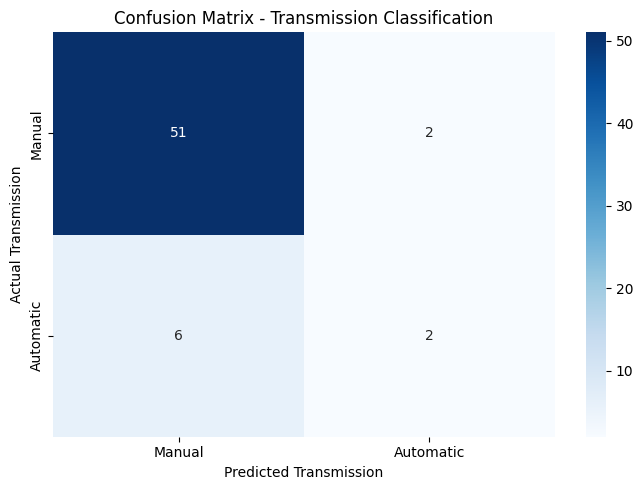

In [18]:
# Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Manual", "Automatic"],
    yticklabels=["Manual", "Automatic"]
)

plt.title("Confusion Matrix - Transmission Classification")
plt.xlabel("Predicted Transmission")
plt.ylabel("Actual Transmission")

plt.tight_layout()
plt.show()

In [19]:
print("Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Manual", "Automatic"]
    )
)

Classification Report:

              precision    recall  f1-score   support

      Manual       0.89      0.96      0.93        53
   Automatic       0.50      0.25      0.33         8

    accuracy                           0.87        61
   macro avg       0.70      0.61      0.63        61
weighted avg       0.84      0.87      0.85        61



In [20]:
# Create prediction comparison table

prediction_results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

# Convert numerical values back to labels

prediction_results["Actual"] = prediction_results["Actual"].map({
    0: "Manual",
    1: "Automatic"
})

prediction_results["Predicted"] = prediction_results["Predicted"].map({
    0: "Manual",
    1: "Automatic"
})

print(prediction_results.head(20))

       Actual  Predicted
0      Manual     Manual
1      Manual     Manual
2      Manual  Automatic
3      Manual     Manual
4      Manual     Manual
5      Manual     Manual
6      Manual     Manual
7      Manual     Manual
8   Automatic  Automatic
9      Manual     Manual
10     Manual     Manual
11     Manual     Manual
12     Manual     Manual
13  Automatic     Manual
14  Automatic     Manual
15  Automatic     Manual
16     Manual     Manual
17     Manual     Manual
18     Manual     Manual
19  Automatic     Manual


In [21]:
# Prediction probabilities

probabilities = model.predict_proba(X_test_scaled)

prediction_results["Manual_Probability"] = probabilities[:, 0]
prediction_results["Automatic_Probability"] = probabilities[:, 1]

prediction_results.head(10)

,Actual,Predicted,Manual_Probability,Automatic_Probability
0,Manual,Manual,0.906518,0.093482
1,Manual,Manual,0.931753,0.068247
2,Manual,Automatic,0.416291,0.583709
3,Manual,Manual,0.897207,0.102793
4,Manual,Manual,0.914156,0.085844
5,Manual,Manual,0.892337,0.107663
6,Manual,Manual,0.687633,0.312367
7,Manual,Manual,0.862561,0.137439
8,Automatic,Automatic,0.342113,0.657887
9,Manual,Manual,0.969841,0.030159


In [22]:
# Examine model coefficients

coefficients = pd.DataFrame({
    "Feature": X_encoded.columns,
    "Coefficient": model.coef_[0]
})

coefficients["Absolute_Coefficient"] = (
    coefficients["Coefficient"].abs()
)

coefficients = coefficients.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

print(coefficients)

                  Feature  Coefficient  Absolute_Coefficient
1           Selling_Price     1.287264              1.287264
7  Seller_Type_Individual     0.361492              0.361492
6        Fuel_Type_Petrol     0.349885              0.349885
5        Fuel_Type_Diesel    -0.197753              0.197753
4                   Owner     0.160535              0.160535
2           Present_Price     0.125247              0.125247
3              Kms_Driven     0.076128              0.076128
0                    Year    -0.029109              0.029109


In [23]:
# Example new vehicle

new_car = pd.DataFrame({
    "Year": [2016],
    "Selling_Price": [5.5],
    "Present_Price": [8.0],
    "Kms_Driven": [30000],
    "Fuel_Type": ["Petrol"],
    "Seller_Type": ["Dealer"],
    "Owner": [0]
})

# Encode categorical variables
new_car_encoded = pd.get_dummies(
    new_car,
    columns=["Fuel_Type", "Seller_Type"],
    drop_first=True
)

# Make sure columns match training data
new_car_encoded = new_car_encoded.reindex(
    columns=X_encoded.columns,
    fill_value=0
)

# Scale
new_car_scaled = scaler.transform(new_car_encoded)

# Prediction
new_prediction = model.predict(new_car_scaled)[0]

# Probability
new_probability = model.predict_proba(new_car_scaled)[0]

# Convert prediction to label
prediction_label = {
    0: "Manual",
    1: "Automatic"
}

print("Predicted Transmission:",
      prediction_label[new_prediction])

print(
    f"Probability of Manual: {new_probability[0] * 100:.2f}%"
)

print(
    f"Probability of Automatic: {new_probability[1] * 100:.2f}%"
)

Predicted Transmission: Manual
Probability of Manual: 94.39%
Probability of Automatic: 5.61%
